In [46]:
from IPython.display import HTML
import math
import random
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

In [24]:
def f(x):
    return 3*x**2 - 4*x + 5
f(3.0)

20.0

In [25]:
xs = np.arange(-6,6,0.25)
print(f'input xs are={xs}')
ys = f(xs)
print(f'output ys are={ys}')

input xs are=[-6.   -5.75 -5.5  -5.25 -5.   -4.75 -4.5  -4.25 -4.   -3.75 -3.5  -3.25
 -3.   -2.75 -2.5  -2.25 -2.   -1.75 -1.5  -1.25 -1.   -0.75 -0.5  -0.25
  0.    0.25  0.5   0.75  1.    1.25  1.5   1.75  2.    2.25  2.5   2.75
  3.    3.25  3.5   3.75  4.    4.25  4.5   4.75  5.    5.25  5.5   5.75]
output ys are=[137.     127.1875 117.75   108.6875 100.      91.6875  83.75    76.1875
  69.      62.1875  55.75    49.6875  44.      38.6875  33.75    29.1875
  25.      21.1875  17.75    14.6875  12.       9.6875   7.75     6.1875
   5.       4.1875   3.75     3.6875   4.       4.6875   5.75     7.1875
   9.      11.1875  13.75    16.6875  20.      23.6875  27.75    32.1875
  37.      42.1875  47.75    53.6875  60.      66.6875  73.75    81.1875]


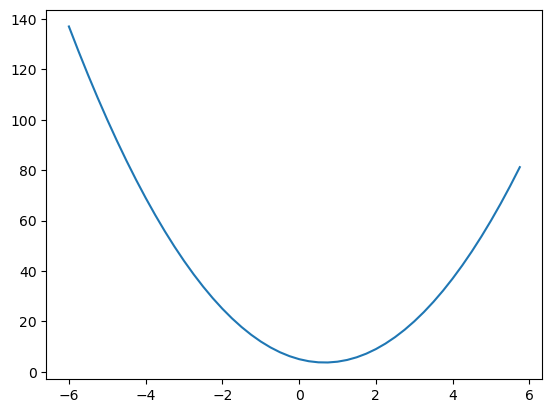

In [26]:
plt.plot(xs,ys)

In [27]:
# simple value object

# the __repr__ function is helping in printing out the values properly, without it we would get hex numbers when printing
class Value:
    def __init__(self, data, _children=(), _op ='', label=''):
        self.data = data
        self.grad = 0.0
        self._backward = lambda: None
        self._prev = set(_children)
        self._op = _op
        self.label = label
        
    def __repr__(self):
        return f"Value(data={self.data})"
        
    def __add__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data + other.data, _children = (self, other), _op = '+') 
        def _backward():
            self.grad += 1.0 * out.grad
            other.grad += 1.0 * out.grad
        out._backward = _backward
        return out
        
    def __mul__(self, other):
        other = other if isinstance(other,Value) else Value(other)
        out = Value(self.data * other.data, _children = (self, other), _op = '*')
        def _backward():
            self.grad += other.data * out.grad
            other.grad += self.data * out.grad
        out._backward = _backward
        return out

    def __pow__(self, other):
        assert isinstance(other, (int, float)), "only supporting int/float powers for now"
        out = Value(self.data**other, (self,), f'**{other}')
        def _backward():
            self.grad +=  other * (self.data ** (other - 1)) * out.grad
            
        out._backward = _backward
        return out

    def __radd__(self, other): # for number + Value
        return self + other
    
    def __rmul__(self, other):    # other * self (swaps the order)
        return self * other

    def __truediv__(self, other):  # self / other
        return self * other**-1

    def __neg__(self):
        return self * -1 # - self

    def __sub__(self, other):  # self - other
        return self + (- other)
    
    def tanh(self):
        x = self.data
        t = (math.exp(2*x) - 1)/(math.exp(2*x) + 1)
        out = Value(t,(self, ),'tanh')
        def _backward():
            self.grad += (1 - t**2) * out.grad
        out._backward = _backward
        return out

    def exp(self):
        x = self.data
        out = Value(math.exp(x),(self,), 'exp')

        def _backward():
            self.grad += out.data * out.grad 
        out._backward = _backward
        return out
        
    def backward(self):
        # made the topological list
        topo = []
        visited = set()
        def build_topo(v):
            if v not in visited:
                visited.add(v)
                for child in v._prev:
                    build_topo(child)
                topo.append(v)
        build_topo(self)

        self.grad = 1.0 # set the output grad to 1
        # go from the reversed order of the topological list
        for node in reversed(topo):
            node._backward()
            
        

In [28]:
a = Value(2.0, label='a')
b = Value(4.0, label='b')
print(a + 1)
print(a*3)
print(4*a)
a.exp()

Value(data=3.0)
Value(data=6.0)
Value(data=8.0)


Value(data=7.38905609893065)

In [29]:
a = Value(2.0, label='a')
b = Value(4.0, label='b')
print(a/b)
a-b

Value(data=0.5)


Value(data=-2.0)

In [30]:
from graphviz import Digraph

def trace(root):
  # builds a set of all nodes and edges in a graph
  nodes, edges = set(), set()
  def build(v):
    if v not in nodes:
      nodes.add(v)
      for child in v._prev:
        edges.add((child, v))
        build(child)
  build(root)
  return nodes, edges
def draw_dot(root):
    dot = Digraph(format='svg', graph_attr={'rankdir': 'LR'})  # LR = left to right

    nodes, edges = trace(root)
    for n in nodes:
        uid = str(id(n))
        # for any value in the graph, create a rectangular ('record') node for it
        dot.node(name=uid, label="{ %s | data %.4f | grad %.4f }" % (n.label, n.data, n.grad), shape='record')

        if n._op:
            # if this value is a result of some operation, create an op node for it
            dot.node(name=uid + n._op, label=n._op)
            # and connect this node to it
            dot.edge(uid + n._op, uid)

    for n1, n2 in edges:
        # connect n1 to the op node of n2
        dot.edge(str(id(n1)), str(id(n2)) + n2._op)

    return dot

In [31]:
#inputs x1,x2
x1 = Value(2.0, label = 'x1')
x2 = Value(0.0, label = 'x2')

#weights w1,w2
w1 = Value(-3.0, label = 'w1')
w2 = Value(1.0, label = 'w2')

# bias of the neuron
b = Value(6.8813735870195432, label = 'b')

x1w1 = x1*w1
x1w1.label='x1*w1'
x2w2 = x2*w2
x2w2.label='x2*w2'

# x1*w1 + x2*w2 + b
x1w1x2w2 = x1w1 + x2w2
x1w1x2w2.label = 'x1w1 + x2w2'
n = x1w1x2w2 + b  # n is the raw activation value without clamping the activation function on it
n.label = 'n'

o = n.tanh() #output
o.label = 'output'

o.backward()

In [49]:
dot = draw_dot(o)
svg = dot.pipe(format='svg').decode('utf-8')

HTML(f"""
<div style="
    width: 100%;
    height: 300px;
    overflow: auto;
">
    <div style="width: 4000px;">
        {svg}
    </div>
</div>
""")

In [54]:
#changing how we define the tanh.. doing it with exponentials

#inputs x1,x2
x1 = Value(2.0, label = 'x1')
x2 = Value(0.0, label = 'x2')

#weights w1,w2
w1 = Value(-3.0, label = 'w1')
w2 = Value(1.0, label = 'w2')

# bias of the neuron
b = Value(6.8813735870195432, label = 'b')

x1w1 = x1*w1
x1w1.label='x1*w1'
x2w2 = x2*w2
x2w2.label='x2*w2'

# x1*w1 + x2*w2 + b
x1w1x2w2 = x1w1 + x2w2
x1w1x2w2.label = 'x1w1 + x2w2'
n = x1w1x2w2 + b  # n is the raw activation value without clamping the activation function on it
n.label = 'n'
# ----------------
e = (2*n).exp()
# o = ((2*n).exp() - 1) / (2*n).exp() + 1 #output
o = (e - 1) / (e + 1)
# ----------------
o.label = 'output'

o.backward()
draw_dot(o) # this is sufficient only using svg to see it better
dot = draw_dot(o) 
svg = dot.pipe(format='svg').decode('utf-8')

HTML(f"""
<div style="
    width: 100%;
    height: 300px;
    overflow: auto;
">
    <div style="width: 4000px;">
        {svg}
    </div>
</div>
""")

In [34]:
# doing the same thing -- the forward and backward pass in pytorch

import torch

In [35]:
# since these inputs are leaf nodes, pytorch assumes that they do not need gradients, so we will have to specify that they need it
# because usually we dont need the gradients for the leaf nodes/inputs -- so it saves time by not calculating it by default
x1 = torch.Tensor([2.0]).double() ;x1.requires_grad = True 
x2 = torch.Tensor([0.0]).double() ;x2.requires_grad = True
w1 = torch.Tensor([-3.0]).double() ;w1.requires_grad = True
w2 = torch.Tensor([1.0]).double() ;w2.requires_grad = True
b = torch.Tensor([6.8813735870195432]).double() ;b.requires_grad = True

n = x1*w1 + x2*w2 + b
out = torch.tanh(n)

print(f'forward pass value = {out.data.item()}')
out.backward()

print("---Calculating gradients---")
print(f"gradient of x2 is {x2.grad.item()}")
print(f"gradient of w2 is {w2.grad.item()}")
print(f"gradient of x1 is {x1.grad.item()}")
print(f"gradient of w1 is {w1.grad.item()}")

forward pass value = 0.7071066904050358
---Calculating gradients---
gradient of x2 is 0.5000001283844369
gradient of w2 is 0.0
gradient of x1 is -1.5000003851533106
gradient of w1 is 1.0000002567688737


In [36]:
out.item()

0.7071066904050358

In [37]:
x1.grad

tensor([-1.5000], dtype=torch.float64)

In [58]:
# building neural networks for our micrograds -- Value objects
class Neuron:

    def __init__(self, nin): # takes in self and number of inputs to that specific neuron
        self.w = [Value(random.uniform(-1,1)) for _ in range(nin)]
        # print("weights ", self.w, "\n")
        self.b = Value(random.uniform(-1,1))
        # print("bias ", self.b, "\n")

    def __call__(self, x):
        # w * x + b
        # print("ziping ", list(zip(self.w, x))) # iterates over the tuples of the two iterators corresponding entries
        act = sum((wi*xi for wi, xi in zip(self.w, x)), self.b) # sum can take in a second parameter, by default its 0.0 but we can just add the bias at the srart for efficiency
        out = act.tanh()
        # print("calculated the forward pass ",out)
        return out

    def parameters(self):
        return self.w + [self.b]

class Layer:
    def __init__(self, nin, nout):  # (each neurons dimension, how many of them I want)
        self.neurons = [Neuron(nin) for _ in range(nout)]

    def __call__(self, x):
        outs = [n(x) for n in self.neurons]
        return outs[0] if len(outs) == 1 else outs

    def parameters(self):
        return [p for neuron in self.neurons for p in neuron.parameters()]

class MLP:
    def __init__(self, nin, nouts):
        sz = [nin] + nouts
        self.layers = [Layer(sz[i], sz[i+1]) for i in range(len(nouts))]

    def __call__(self, x):
        for layer in self.layers:
            x = layer(x)
        return x
        
    def parameters(self):
        return [p for layer in self.layers for p in layer.parameters()]

# i want to build an MLP with 3 inputs, 2 layers of 4 neurons and an output neuron
# x = [2.0, 3.0, -1.0] # 3 input neurons -- 3D input
# # n = Neuron(3)
# # defining a layer of neurons -- MLP
# n = MLP(3, [4, 4, 1]) # we want 3 inputs going into ---> 2 layers of 4 and an output unit
# n(x)

In [86]:
x = [2.0, 3.0, -1.0]
n = MLP(3, [4, 4, 1]) # we want 3 inputs going into ---> 2 layers of 4 and an output unit
n(x)
# n.parameters()

Value(data=0.8762354178567101)

In [87]:
len(n.parameters())

41

In [93]:
dot = draw_dot(n(x))
svg = dot.pipe(format='svg').decode('utf-8')

HTML(f"""
<div style="
    width: 100%;
    height: 800px;
    overflow: auto;
">
    <div style="width: 4000px;">
        {svg}
    </div>
</div>
""")

In [89]:
# simple dataset-- has 4 examples, 4 possible inputs into the NN. 4 desired targets

xs = [
    [2.0, 3.0, -1.0],
    [3.0, -1.0, 0.5],
    [0.5, 1.0, 1.0],
    [1.0, 1.0, 1.0]
]
ys = [1.0, -1.0, -1.0, 1.0] # desired targets

In [90]:
# now we have to tune the weights so that the values becomes what we want (i.e. the targets)
# we define a single number that somehow measures/represents the total performance of the NN. We call it the loss
# we will define it as the mean squared error
individual_loss = [(yout - ygt)**2 for ygt, yout in zip(ys, ypred)] # loss for each prediction upon each set of inputs
individual_loss

[Value(data=1.2909710211309544),
 Value(data=1.208185296137833),
 Value(data=0.7210086551351146),
 Value(data=1.2159830670664058)]

In [91]:
# so the final loss/ total loss would be the sum of all these losses
# getting their predictions
ypred = [n(x) for x in xs] # lets see what the model thinks right now as to what the prediction is 
# print(ypred)
loss = sum([(yout - ygt)**2 for ygt, yout in zip(ys, ypred)])
loss

Value(data=6.5010743549096555)

In [157]:
ypred = [n(x) for x in xs] # lets see what the model thinks right now as to what the prediction is 
# print(ypred)
loss = sum([(yout - ygt)**2 for ygt, yout in zip(ys, ypred)])
loss

Value(data=4.045185248190706)

In [155]:
loss.backward()

In [100]:
# n.layers[0].neurons[0].w[0].grad

In [101]:
# n.layers[0].neurons[0].w[0].data

In [159]:
# we want to nudge all the parameters by a tiny amount || and we always want to go on the opposite direction of the gradient
# because the gradient always points towards where the loss is higher
for p in n.parameters():
    p.data += - 0.01 * p.grad

In [153]:
n.layers[0].neurons[0].w[0].data

-0.14302645099817018

In [160]:
ypred

[Value(data=0.7564877581792423),
 Value(data=-0.999845640071227),
 Value(data=0.9964665414574158),
 Value(data=0.9971084107807812)]

In [163]:
# now when the ypred is very close to out GTs, this is the settings of weights and biases that makes out network predict the desired targets
n.parameters() 


[Value(data=-0.5256113175530348),
 Value(data=0.49202014888802703),
 Value(data=3.500870940857722),
 Value(data=1.8209901446479462),
 Value(data=0.027677537238024623),
 Value(data=-1.6995762715763605),
 Value(data=0.37327504792256705),
 Value(data=0.4035305178938462),
 Value(data=-0.2980178315601907),
 Value(data=-2.061414895430299),
 Value(data=0.5402343446081393),
 Value(data=-0.06746741879739689),
 Value(data=0.9465938955769234),
 Value(data=2.2045677146289857),
 Value(data=-3.3625820495531955),
 Value(data=-1.5378297881978833),
 Value(data=-1.582098947934791),
 Value(data=-2.5686031073815507),
 Value(data=-2.0619363856546387),
 Value(data=1.8317795319948995),
 Value(data=-1.7104727150505692),
 Value(data=-0.06620845723148985),
 Value(data=1.606368625118919),
 Value(data=0.8480311125337712),
 Value(data=-1.1903068788563886),
 Value(data=0.49478211759694507),
 Value(data=2.2491159634218127),
 Value(data=0.7539101381510278),
 Value(data=0.4629362696005169),
 Value(data=-1.995867593054

In [68]:
dot = draw_dot(loss)
svg = dot.pipe(format='svg').decode('utf-8')

HTML(f"""
<div style="
    width: 100%;
    height: 800px;
    overflow: auto;
">
    <div style="width: 4000px;">
        {svg}
    </div>
</div>
""")